# 09 · Ablation studies (Step 6)

Every ablation changes **one** thing in a selected configuration and is scored on the same rolling folds as a 5-seed ensemble. No ablation uses calibration or test data. A difference is read against two noise levels: the mean seed SD (whisker in the figure) and the number of folds that move in the same direction.

| Question | Ablations |
|---|---|
| Do learned embeddings help? | one-hot instead of embeddings; width 2/4/8/16 |
| Can embeddings exploit IDs a one-hot LogReg cannot? | + tail, flight and origin-hour IDs |
| Is the regularisation needed? | no dropout / weight decay; no early stopping |
| Which Phase 1 feature groups matter to a network? | − schedule, − congestion, − entity history, − day-level history |
| Do learned sequences replace hand-built history (the brief's gap)? | GRU without the hand-crafted history features; window 7 / 14 days |
| Which part of the hybrid carries the value? | Wide & Deep without GRU; without embeddings |

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().resolve().parent
for p in (ROOT / 'src', ROOT.parent / 'phase1' / 'src'):
    sys.path.insert(0, str(p))

import aerocast_dl  # torch before XGBoost (OpenMP)
import numpy as np, pandas as pd
from IPython.display import Image, display
from aerocast_dl import config, pipeline
R, F = config.RESULTS_DIR, config.FIGURES_DIR
pd.set_option('display.precision', 4)


In [2]:
abl = pipeline.ablation_table()
saved = pd.read_csv(R / 'ablation.csv')
pd.testing.assert_frame_equal(abl, saved, check_dtype=False)
abl['beyond_seed_noise'] = abl['delta'].abs() > abl['seed_sd']
abl[['label', 'base', 'base_cv', 'cv', 'delta', 'folds_improved', 'seed_sd', 'beyond_seed_noise']].sort_values('delta')

,label,base,base_cv,cv,delta,folds_improved,seed_sd,beyond_seed_noise
7,MLP: no early stopping,mlp,0.4655,0.4308,-0.0347,0,0.0065,True
10,MLP: − entity history,mlp,0.4655,0.4485,-0.0170,0,0.0038,True
12,GRU: replaces hand-crafted history,gru,0.4672,0.4525,-0.0146,0,0.0055,True
9,MLP: − congestion features,mlp,0.4655,0.4557,-0.0098,0,0.0053,True
11,MLP: − day-level history,mlp,0.4655,0.4559,-0.0096,1,0.0036,True
1,MLP: embedding width 2,mlp,0.4655,0.4619,-0.0036,0,0.0058,False
8,MLP: − schedule features,mlp,0.4655,0.4631,-0.0024,2,0.0035,False
4,MLP: embedding width 16,mlp,0.4655,0.4634,-0.0021,1,0.0040,False
2,MLP: embedding width 4,mlp,0.4655,0.4636,-0.0019,0,0.0042,False
3,MLP: embedding width 8,mlp,0.4655,0.4638,-0.0017,1,0.0037,False


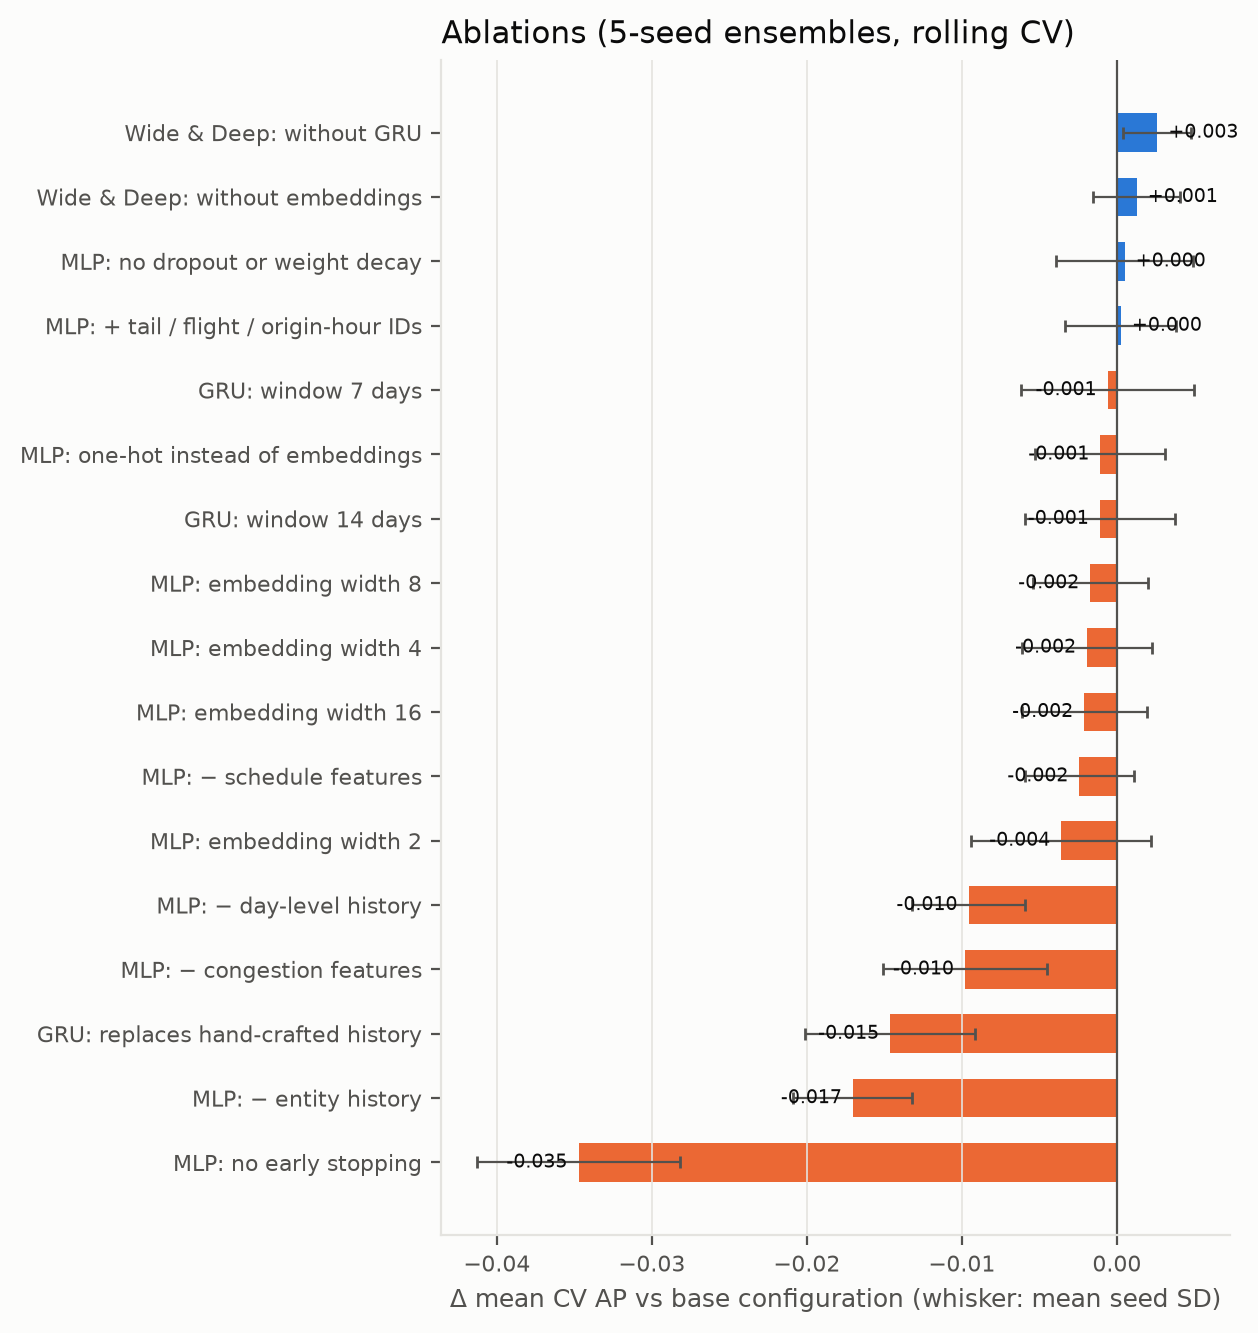

In [3]:
display(Image(F / 'ablation_cv.png', width=700))